# Exploratory Data Analysis: NYC Airbnb 2019
Dataset: AB_NYC_2019_cleaned.csv (cleaned in Task 1)
Goal: find patterns, trends, and anomalies in NYC Airbnb listings, and summarize 5+ useful insights.

In [1]:
import pandas as pd 
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv(r"C:\Users\manso\OneDrive\Documents\SWYNEX-Exploratory-Data-Analysis\data\AB_NYC_2019_cleaned.csv")
df.shape

(48870, 16)

In [3]:
df.head()

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,0.00,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 48870 entries, 0 to 48869
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              48870 non-null  int64  
 1   name                            48870 non-null  str    
 2   host_id                         48870 non-null  int64  
 3   host_name                       48870 non-null  str    
 4   neighbourhood_group             48870 non-null  str    
 5   neighbourhood                   48870 non-null  str    
 6   latitude                        48870 non-null  float64
 7   longitude                       48870 non-null  float64
 8   room_type                       48870 non-null  str    
 9   price                           48870 non-null  int64  
 10  minimum_nights                  48870 non-null  int64  
 11  number_of_reviews               48870 non-null  int64  
 12  last_review                     38827 non-n

In [6]:
df.groupby('neighbourhood_group')['price'].mean().sort_values(ascending=False)

neighbourhood_group
Manhattan        196.888011
Brooklyn         124.452238
Staten Island    114.812332
Queens            99.493997
Bronx             87.577064
Name: price, dtype: float64

## Insight 1: Manhattan is by far the most expensive borough
Manhattan listings average 196.89 USD/night — nearly 60% higher than Brooklyn (124.45 USD) 
and more than double the Bronx (87.58 USD, the cheapest borough). This likely reflects 
Manhattan's central location and tourist demand.

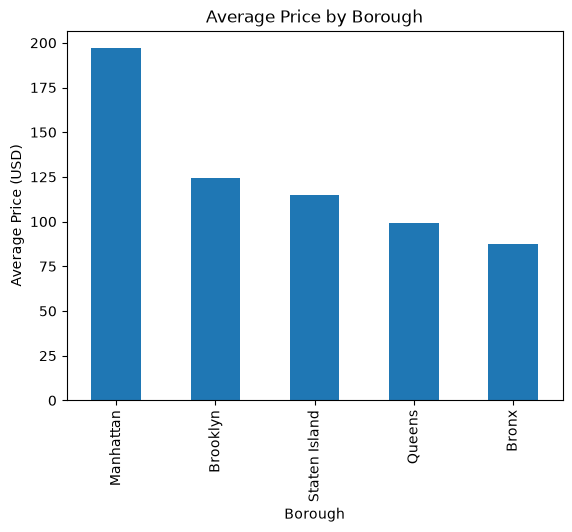

In [11]:
avg_price = df.groupby('neighbourhood_group')['price'].mean().sort_values(ascending=False)

avg_price.plot(kind='bar', title='Average Price by Borough')
plt.ylabel('Average Price (USD)')
plt.xlabel('Borough')
plt.show()

In [12]:
df['room_type'].value_counts()

room_type
Entire home/apt    25398
Private room       22315
Shared room         1157
Name: count, dtype: int64

In [13]:
df.groupby('room_type')['price'].mean().sort_values(ascending=False)

room_type
Entire home/apt    211.823293
Private room        89.815192
Shared room         70.214347
Name: price, dtype: float64

## Insight 2: Entire homes dominate listings and command the highest prices
Entire home/apt listings make up over half of all listings (25,398 of 48,870) and average 
211.82 USD/night — more than double a private room (89.82 USD) and three times a shared room 
(70.21 USD). This suggests most hosts and guests on this platform favor whole-unit rentals 
over shared accommodations.

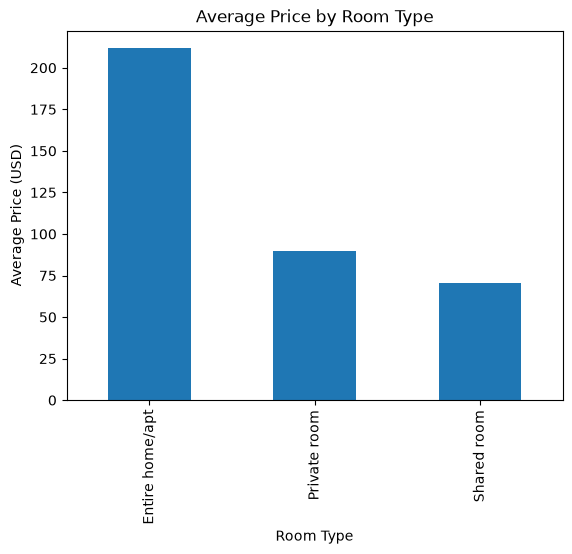

In [15]:
df.groupby('room_type')['price'].mean().sort_values(ascending=False).plot(kind='bar', title='Average Price by Room Type')
plt.ylabel('Average Price (USD)')
plt.xlabel('Room Type')
plt.show()

In [19]:
(df['availability_365'] == 0).sum()

np.int64(17530)

In [18]:
df['availability_365'].describe()

count    48870.000000
mean       112.728443
std        131.596499
min          0.000000
25%          0.000000
50%         45.000000
75%        227.000000
max        365.000000
Name: availability_365, dtype: float64

## Insight 3: Over a third of listings are inactive
17,530 listings (about 36% of all 48,870) show 0 days of availability in the next year — 
meaning they are not currently bookable at all. The median listing is available just 45 
days a year, while only the top quarter are available 227+ days. This suggests a large 
portion of listings on the platform are inactive, paused, or rarely rented, rather than 
actively competing for bookings.

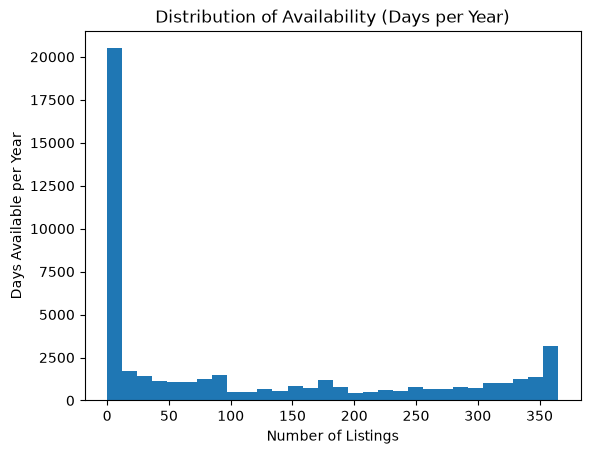

In [20]:
df['availability_365'].plot(kind='hist' , bins=30 , title='Distribution of Availability (Days per Year)')
plt.ylabel('Days Available per Year')
plt.xlabel('Number of Listings')
plt.show()

In [21]:
df['price'].corr(df['number_of_reviews'])

np.float64(-0.04793064647987519)

In [24]:
df['price_range'] = pd.cut(df['price'], bins=[0, 50, 100, 200, 500, 10000], labels=['0-50', '51-100', '101-200', '201-500', '500+'])

df.groupby('price_range')['number_of_reviews'].mean()

price_range
0-50       19.856576
51-100     26.096752
101-200    25.039573
201-500    17.450531
500+       10.800766
Name: number_of_reviews, dtype: float64

## Insight 4: Mid-priced listings get the most reviews, not the cheapest ones
The overall correlation between price and number of reviews is nearly zero (-0.05), suggesting 
no simple straight-line relationship. However, grouping listings by price range reveals a clearer 
pattern: reviews peak in the 51-100 USD range (avg 26.1 reviews) and decline steadily above 200 USD, 
dropping to just 10.8 reviews for listings over 500 USD. This suggests guests favor well-priced, 
mid-range listings, while very expensive listings attract fewer bookings and reviews.

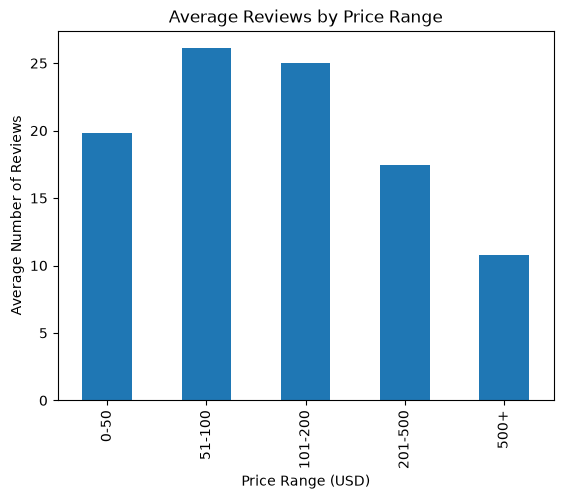

In [29]:
df.groupby('price_range')['number_of_reviews'].mean().plot(kind='bar', title='Average Reviews by Price Range')
plt.ylabel('Average Number of Reviews')
plt.xlabel('Price Range (USD)')
plt.show()

In [26]:
df['neighbourhood'].value_counts().head(10)

neighbourhood
Williamsburg          3917
Bedford-Stuyvesant    3709
Harlem                2656
Bushwick              2461
Upper West Side       1971
Hell's Kitchen        1958
East Village          1853
Upper East Side       1798
Crown Heights         1563
Midtown               1544
Name: count, dtype: int64

In [27]:
top_10 = df['neighbourhood'].value_counts().head(10).index

df[df['neighbourhood'].isin(top_10)].groupby('neighbourhood')['price'].mean().sort_values(ascending=False)

neighbourhood
Midtown               282.740285
Upper West Side       210.918316
Hell's Kitchen        204.794178
Upper East Side       188.948276
East Village          186.083108
Williamsburg          143.857033
Harlem                118.998117
Crown Heights         112.520154
Bedford-Stuyvesant    107.809922
Bushwick               84.891508
Name: price, dtype: float64

## Insight 5: Listing volume and price don't move together across top neighbourhoods
Williamsburg has the most listings of any neighbourhood (3,917), but its average price (143.86 USD) 
ranks only 6th among the top 10 busiest neighbourhoods. Midtown, despite having the fewest listings 
in the top 10 (1,544), has by far the highest average price (282.74 USD) — nearly double Williamsburg's. 
This shows that a neighbourhood's popularity (listing count) and its pricing power are driven by 
different factors, likely location and tourist appeal rather than just supply.

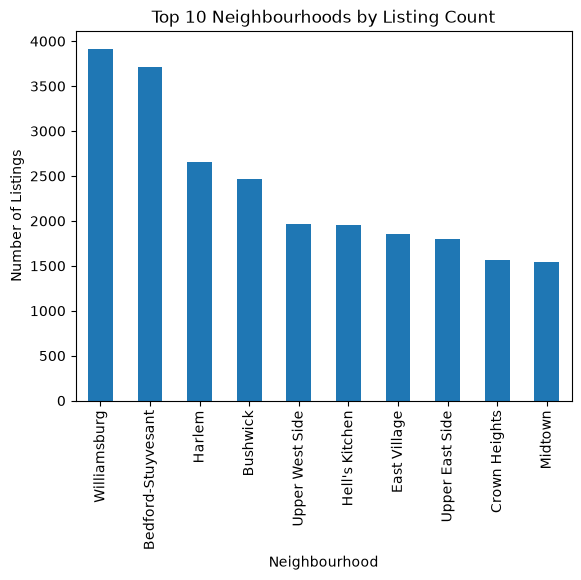

In [28]:
df['neighbourhood'].value_counts().head(10).plot(kind='bar', title='Top 10 Neighbourhoods by Listing Count')
plt.ylabel('Number of Listings')
plt.xlabel('Neighbourhood')
plt.show()